# AI-Powered Phishing Website Detection and Classification System
## Using Machine Learning and Deep Learning
**Course / Laboratory Project:** Artificial Intelligence in Cybersecurity  
**System Designation:** PHISHGUARD AI  
**Author / Engineering Role:** Senior AI Cybersecurity Researcher & ML Engineer

---

### Abstract
Phishing constitutes one of the most prolific and devastating social engineering cyber threats in contemporary computer networks, leading to identity theft, credential harvesting, and billions of dollars in organizational losses. This project engineers an enterprise-grade AI threat detection pipeline that classifies web resources as either **Legitimate (Class 0)** or **Phishing (Class 1)** based on 30 multidimensional structural, behavioral, and domain indicators. We benchmark three models: **Logistic Regression**, **Decision Tree Classifier**, and **Multi-Layer Perceptron (MLP) Deep Artificial Neural Network**, paired with feature importance attribution and an Ethical AI decision-boundary framework.

## 1. Problem Statement & Threat Vector Landscape
Traditional signature-based detection mechanisms (e.g., static blacklists and heuristic domain reputation lists) suffer from acute latency bottlenecks when confronting modern phishing campaigns. Attackers frequently register disposable domain names, exploit free SSL certificates (e.g. Let's Encrypt), manipulate URL syntax (typosquatting, hyphens, URL shorteners), and clone authentication forms.

**Primary Objectives:**
1. Automatically acquire and preprocess the standard benchmark UCI Phishing Websites Dataset (ID: 327).
2. Clean, validate, and conduct comprehensive Exploratory Data Analysis (EDA) on 30 cyber security features.
3. Normalize target classifications into standard threat convention (0 = Legitimate, 1 = Phishing).
4. Implement, tune, and cross-evaluate:
   - Baseline Linear Model: **Logistic Regression**
   - Non-Linear Rule-Based Model: **Decision Tree Classifier**
   - Deep Learning Architecture: **Multi-Layer Perceptron (MLPClassifier)**
5. Analyze feature importance across models (Gini Importance, Coefficients, Permutation Importance).
6. Perform Ethical AI threshold analysis addressing False Positive (operational friction) vs False Negative (security breach) trade-offs.

## 2. Environment Setup & Core Dependencies
Import necessary scientific, machine learning, and visualization libraries.

In [1]:
import os
import sys
import time
import json
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve,
    confusion_matrix, classification_report
)
from sklearn.inspection import permutation_importance

# Plotting configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print("Core libraries successfully imported.")

Core libraries successfully imported.


## 3. Dataset Acquisition & Attribution
- **Source:** UCI Machine Learning Repository
- **Dataset Name:** Phishing Websites Dataset
- **UCI ID:** 327
- **Official URL:** [https://archive.ics.uci.edu/dataset/327/phishing+websites](https://archive.ics.uci.edu/dataset/327/phishing+websites)
- **Creators:** Rami Mohammad, Fadi Thabtah, Lee McCluskey (2012)
- **Total Records:** 11,055 instances
- **Features:** 30 handcrafted website attributes categorized across 4 dimensions:
  1. *Address Bar Features* (e.g., `having_ip_address`, `url_length`, `prefix_suffix`, `sslfinal_state`)
  2. *Abnormal Request Features* (e.g., `url_of_anchor`, `links_in_tags`, `sfh`, `request_url`)
  3. *HTML & JavaScript Features* (e.g., `redirect`, `iframe`, `popupwindow`, `on_mouseover`)
  4. *Domain & External Reputation* (e.g., `web_traffic`, `page_rank`, `google_index`, `age_of_domain`)

Let's load the raw dataset locally or fetch programmatically.

In [2]:
raw_data_path = "../data/raw/phishing_raw.csv" if os.path.exists("../data/raw/phishing_raw.csv") else "data/raw/phishing_raw.csv"

if os.path.exists(raw_data_path):
    df_raw = pd.read_csv(raw_data_path)
    print(f"Dataset successfully loaded from: {raw_data_path}")
else:
    from ucimlrepo import fetch_ucirepo
    print("Fetching dataset ID 327 from UCI...")
    ds = fetch_ucirepo(id=327)
    df_raw = pd.concat([ds.data.features, ds.data.targets], axis=1)

print(f"Raw Dataset Dimensions: {df_raw.shape[0]:,} instances, {df_raw.shape[1]} attributes")
df_raw.head()

Dataset successfully loaded from: data/raw/phishing_raw.csv
Raw Dataset Dimensions: 11,055 instances, 31 attributes


,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,...,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report,result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


## 4. Exploratory Data Analysis (EDA)
Inspect dataset schema, missing values, duplicates, and statistical distributions.

In [3]:
print("=== DATASET INFORMATION ===")
df_raw.info()

print("\n=== MISSING VALUE AUDIT ===")
missing_sum = df_raw.isnull().sum().sum()
print(f"Total Missing Values: {missing_sum}")

print("\n=== DUPLICATE RECORD AUDIT ===")
dup_sum = df_raw.duplicated().sum()
print(f"Total Identical Rows: {dup_sum:,} (common in tabular discrete security telemetry)")

print("\n=== ORIGINAL TARGET DISTRIBUTION ===")
target_col = 'result'
print(df_raw[target_col].value_counts())

=== DATASET INFORMATION ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11055 entries, 0 to 11054
Data columns (total 31 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   having_ip_address           11055 non-null  int64
 1   url_length                  11055 non-null  int64
 2   shortining_service          11055 non-null  int64
 3   having_at_symbol            11055 non-null  int64
 4   double_slash_redirecting    11055 non-null  int64
 5   prefix_suffix               11055 non-null  int64
 6   having_sub_domain           11055 non-null  int64
 7   sslfinal_state              11055 non-null  int64
 8   domain_registration_length  11055 non-null  int64
 9   favicon                     11055 non-null  int64
 10  port                        11055 non-null  int64
 11  https_token                 11055 non-null  int64
 12  request_url                 11055 non-null  int64
 13  url_of_anchor               11055

## 5. Target Label Normalization & Preprocessing
In the original UCI dataset:
- `+1` represents **Legitimate Websites**
- `-1` represents **Phishing Websites**

To adhere to standard cybersecurity paradigms where **Class 1 represents the Threat** and **Class 0 represents Benign Traffic**, we normalize the target labels:
- `0 = Legitimate Website` (Original Result = +1)
- `1 = Phishing Website` (Original Result = -1)

In [4]:
# Standardize column names
df_clean = df_raw.copy()
df_clean.columns = [c.lower().strip().replace(' ', '_').replace('-', '_') for c in df_clean.columns]

# Separate features and target
X = df_clean.drop(columns=['result'])
y_raw = df_clean['result']

# Normalize target: 1 -> 0 (Legit), -1 -> 1 (Phishing)
y = y_raw.map({1: 0, -1: 1, '1': 0, '-1': 1}).astype(int)

print(f"Normalized Target Distribution:")
print(f"  Class 0 (Legitimate Websites): {(y == 0).sum():,} ({(y == 0).mean()*100:.2f}%)")
print(f"  Class 1 (Phishing Websites):   {(y == 1).sum():,} ({(y == 1).mean()*100:.2f}%)")

Normalized Target Distribution:
  Class 0 (Legitimate Websites): 6,157 (55.69%)
  Class 1 (Phishing Websites):   4,898 (44.31%)


## 6. Comprehensive Security Visualizations
We render distribution analysis, correlation heatmap, and comparative attribute breakdowns.

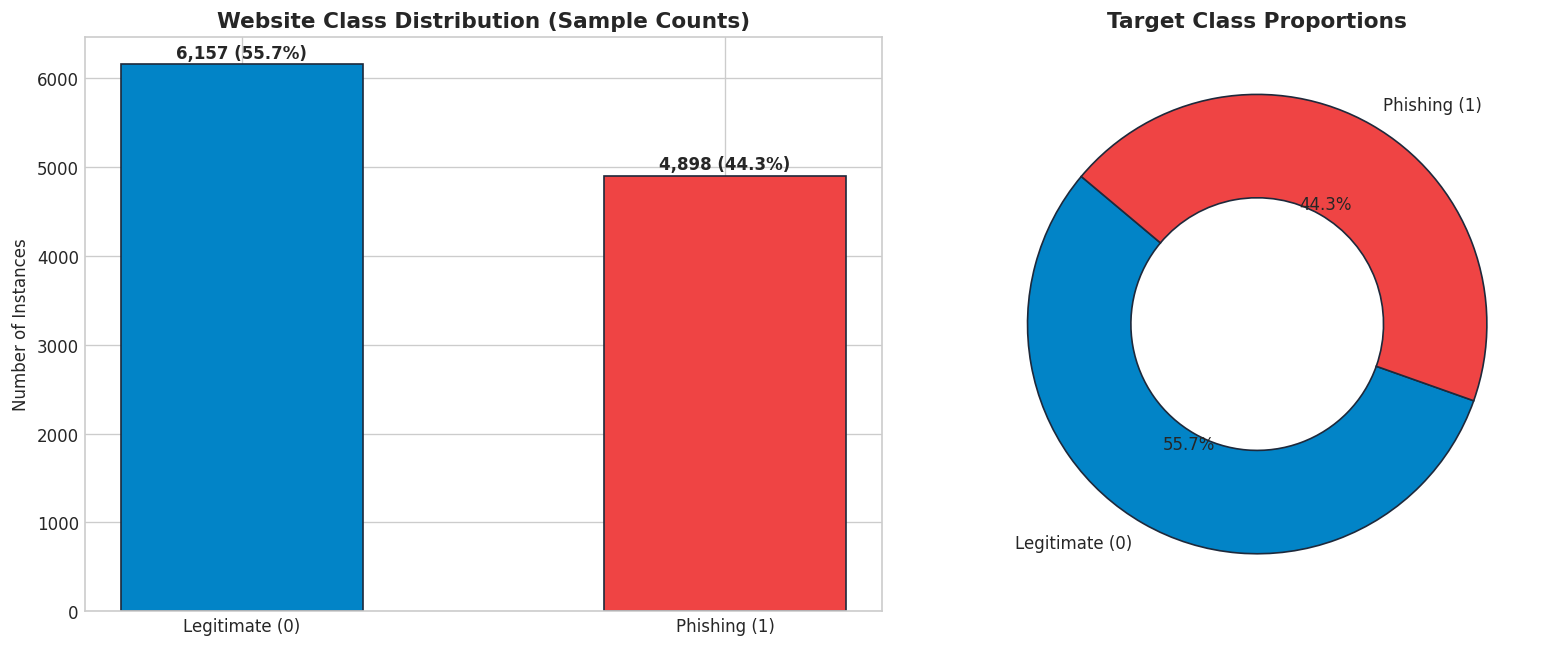

In [5]:
# 1. Class Distribution Bar & Donut
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=120)

# Bar plot
counts = y.value_counts().sort_index()
axes[0].bar(['Legitimate (0)', 'Phishing (1)'], counts.values, color=['#0284c7', '#ef4444'], width=0.5, edgecolor='#1e293b')
axes[0].set_title('Website Class Distribution (Sample Counts)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Number of Instances')
for idx, c in enumerate(counts.values):
    axes[0].annotate(f'{c:,} ({(c/len(y))*100:.1f}%)', xy=(idx, c), xytext=(0, 4), textcoords="offset points", ha='center', fontweight='bold')

# Donut plot
axes[1].pie(counts.values, labels=['Legitimate (0)', 'Phishing (1)'], autopct='%1.1f%%',
            startangle=140, colors=['#0284c7', '#ef4444'], wedgeprops=dict(width=0.45, edgecolor='#1e293b'))
axes[1].set_title('Target Class Proportions', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

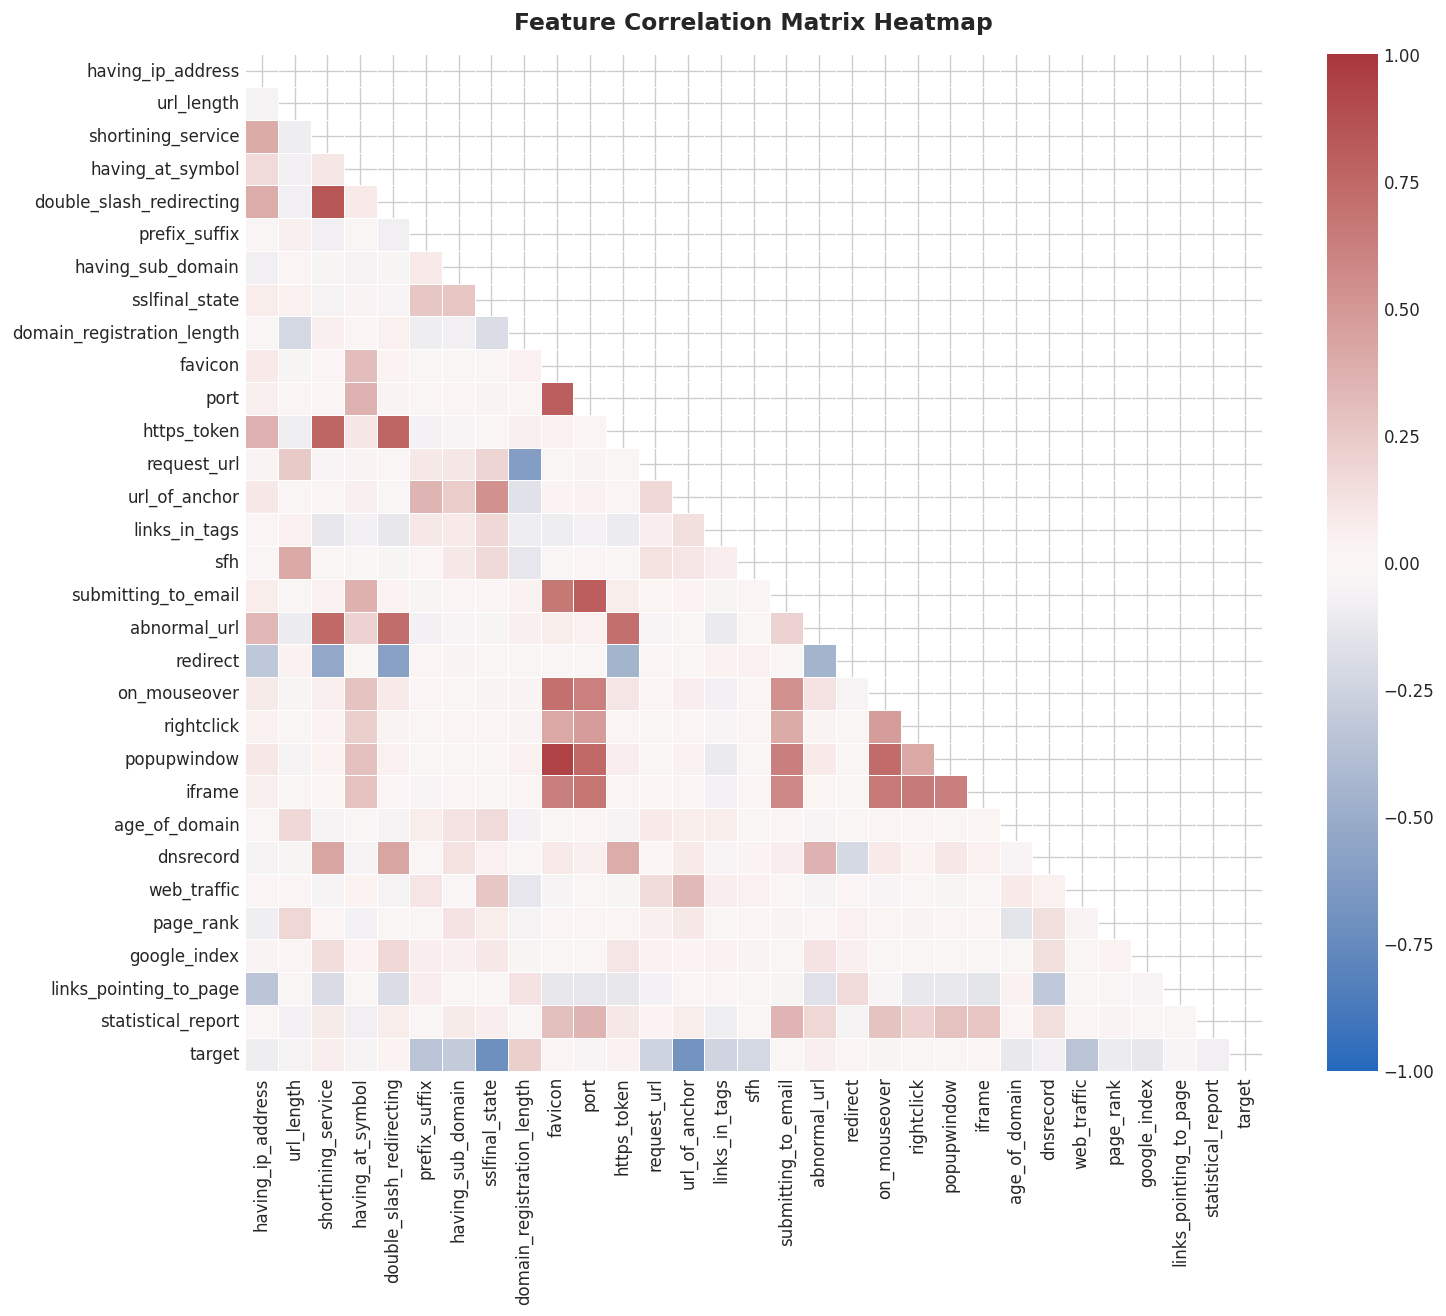

In [6]:
# 2. Correlation Heatmap
plt.figure(figsize=(14, 11), dpi=120)
corr_matrix = pd.concat([X, y.rename('target')], axis=1).corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap='vlag', vmin=-1, vmax=1, annot=False, square=True, linewidths=0.5)
plt.title('Feature Correlation Matrix Heatmap', fontsize=14, fontweight='bold', pad=15)
plt.show()

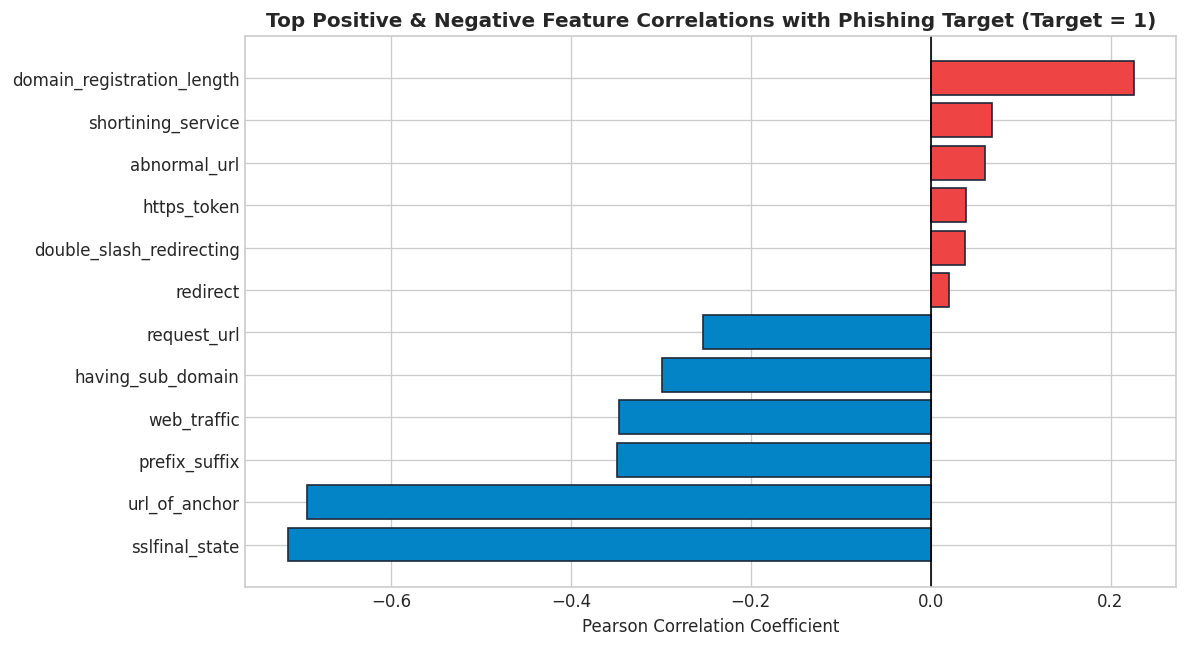

In [7]:
# 3. Top Correlated Attributes with Phishing Target
target_corr = corr_matrix['target'].drop('target').sort_values()
top_correlated = pd.concat([target_corr.head(6), target_corr.tail(6)])

plt.figure(figsize=(10, 5.5), dpi=120)
colors = ['#0284c7' if val < 0 else '#ef4444' for val in top_correlated.values]
plt.barh(top_correlated.index, top_correlated.values, color=colors, edgecolor='#1e293b')
plt.axvline(0, color='black', linewidth=1)
plt.title('Top Positive & Negative Feature Correlations with Phishing Target (Target = 1)', fontsize=12, fontweight='bold')
plt.xlabel('Pearson Correlation Coefficient')
plt.tight_layout()
plt.show()

## 7. Stratified Train-Test Splitting & Pipeline
To prevent data leakage, scaling parameters (mean and standard deviation) are learned **strictly on the training partition (80%)** and applied to the holdout test set (20%).

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Standard scaler fitted on X_train only
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns)

print(f"Stratified Split Summary:")
print(f"  Training Set: {X_train.shape[0]:,} samples (Phishing: {y_train.sum():,})")
print(f"  Testing Set:  {X_test.shape[0]:,} samples (Phishing: {y_test.sum():,})")

Stratified Split Summary:
  Training Set: 8,844 samples (Phishing: 3,918)
  Testing Set:  2,211 samples (Phishing: 980)


## 8. Machine Learning Model 1: Logistic Regression
Logistic Regression models the log-odds of a website being phishing as a linear combination of its security features.
- Scaled input features
- L2 regularization penalty
- Solver: L-BFGS

In [9]:
lr_model = LogisticRegression(C=1.0, max_iter=1000, random_state=42)

t0 = time.perf_counter()
lr_model.fit(X_train_scaled, y_train)
lr_train_time = time.perf_counter() - t0

t1 = time.perf_counter()
y_pred_lr = lr_model.predict(X_test_scaled)
lr_pred_time = time.perf_counter() - t1
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

print(f"Logistic Regression Trained in {lr_train_time:.4f}s | Prediction in {lr_pred_time:.4f}s")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_lr):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_lr):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_lr):.4f}")

Logistic Regression Trained in 0.0345s | Prediction in 0.0040s
Accuracy:  0.9281
Precision: 0.9344
Recall:    0.9010
F1-Score:  0.9174
ROC-AUC:   0.9785


## 9. Machine Learning Model 2: Decision Tree Classifier
Decision Trees recursively partition feature space based on Gini impurity gain, forming transparent hierarchical security rules.
- Criterion: Gini
- Max Depth: 12
- Min Samples Split: 5

In [10]:
dt_model = DecisionTreeClassifier(criterion='gini', max_depth=12, min_samples_split=5, random_state=42)

t0 = time.perf_counter()
dt_model.fit(X_train, y_train)
dt_train_time = time.perf_counter() - t0

t1 = time.perf_counter()
y_pred_dt = dt_model.predict(X_test)
dt_pred_time = time.perf_counter() - t1
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

print(f"Decision Tree Trained in {dt_train_time:.4f}s | Prediction in {dt_pred_time:.4f}s")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_dt):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_dt):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_dt):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_dt):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_dt):.4f}")

Decision Tree Trained in 0.0255s | Prediction in 0.0030s
Accuracy:  0.9643
Precision: 0.9659
Recall:    0.9531
F1-Score:  0.9594
ROC-AUC:   0.9850


## 10. Deep Learning Model: Multi-Layer Perceptron (MLP) Neural Network
A feedforward deep neural network architecture capable of learning complex non-linear feature interactions.
- Architecture: Input (30) $\to$ Hidden Layer 1 (64 neurons, ReLU) $\to$ Hidden Layer 2 (32 neurons, ReLU) $\to$ Output (1 neuron, Sigmoid/Softmax)
- Optimizer: Adam (Initial learning rate: 0.001)
- Regularization: Early stopping on validation loss fraction (10%) with L2 penalty $\alpha = 10^{-4}$

In [11]:
mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    alpha=0.0001,
    learning_rate_init=0.001,
    max_iter=350,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=42
)

t0 = time.perf_counter()
mlp_model.fit(X_train_scaled, y_train)
mlp_train_time = time.perf_counter() - t0

t1 = time.perf_counter()
y_pred_mlp = mlp_model.predict(X_test_scaled)
mlp_pred_time = time.perf_counter() - t1
y_prob_mlp = mlp_model.predict_proba(X_test_scaled)[:, 1]

print(f"MLP Neural Network Trained in {mlp_train_time:.4f}s | Prediction in {mlp_pred_time:.4f}s")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_mlp):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_mlp):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_mlp):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_mlp):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_mlp):.4f}")

MLP Neural Network Trained in 2.2390s | Prediction in 0.0049s
Accuracy:  0.9656
Precision: 0.9699
Recall:    0.9520
F1-Score:  0.9609
ROC-AUC:   0.9944


## 11. Neural Network Convergence & Loss Curve
We inspect the training loss trajectory across optimization epochs to verify absence of pathological overfitting.

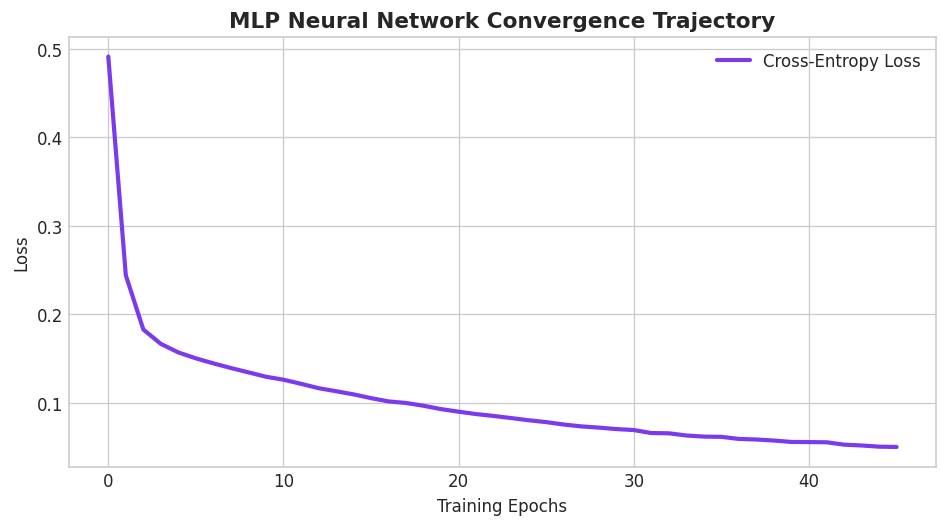

In [12]:
plt.figure(figsize=(8, 4.5), dpi=120)
plt.plot(mlp_model.loss_curve_, color='#7c3aed', linewidth=2.5, label='Cross-Entropy Loss')
plt.title('MLP Neural Network Convergence Trajectory', fontsize=13, fontweight='bold')
plt.xlabel('Training Epochs')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

## 12. Confusion Matrix Diagnostics (TP, TN, FP, FN)
In cybersecurity triage:
- **True Negative (TN):** Legitimate website correctly permitted.
- **False Positive (FP):** Legitimate website incorrectly blocked (causes operational friction).
- **False Negative (FN):** Phishing website missed / slipped past filters (**critical security hazard**).
- **True Positive (TP):** Phishing website successfully detected and quarantined.

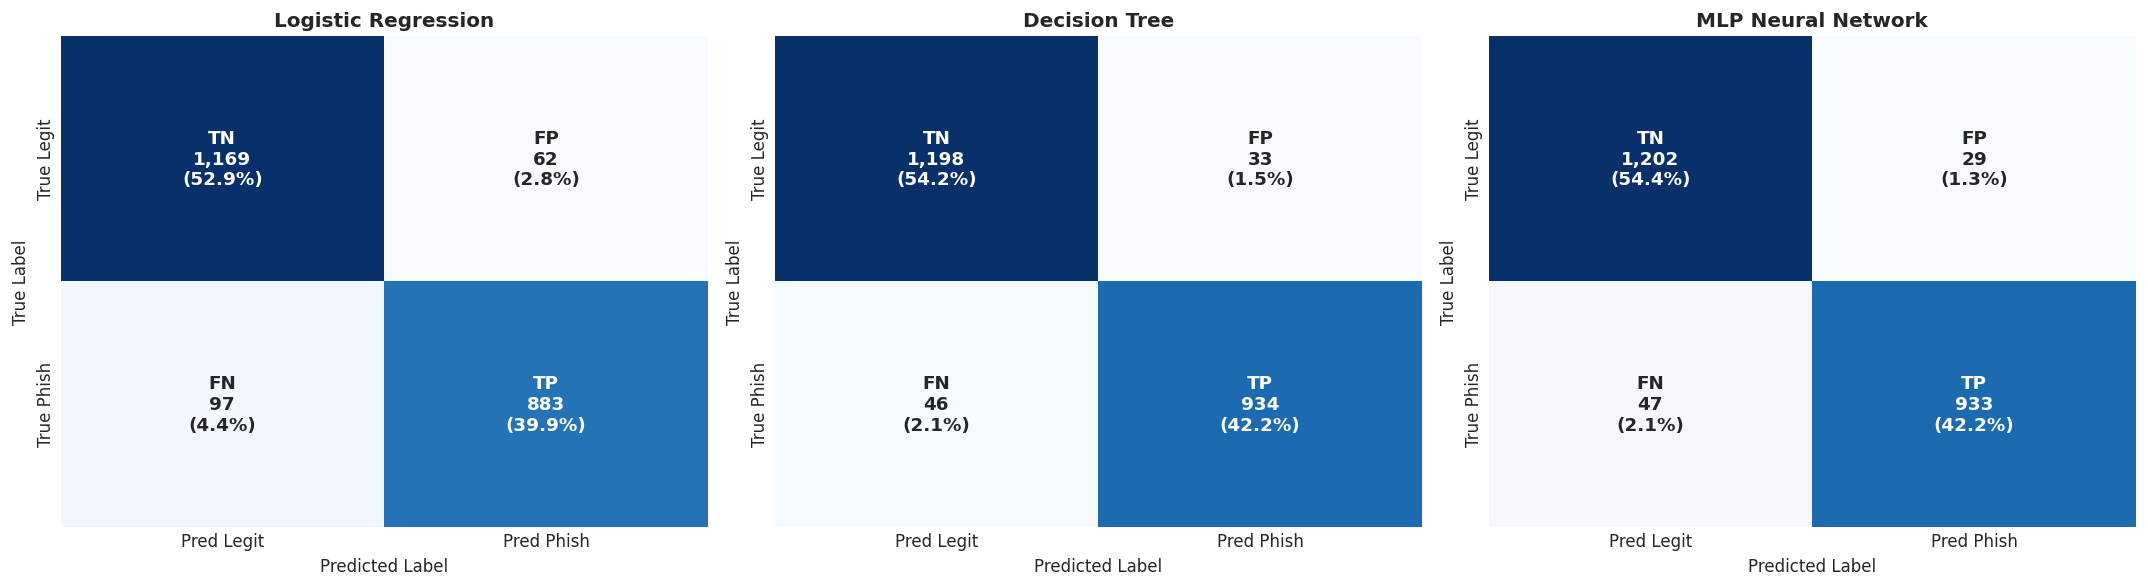

In [13]:
models_preds = {
    'Logistic Regression': (y_pred_lr, y_prob_lr),
    'Decision Tree': (y_pred_dt, y_prob_dt),
    'MLP Neural Network': (y_pred_mlp, y_prob_mlp)
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=120)

for idx, (m_name, (pred, prob)) in enumerate(models_preds.items()):
    cm = confusion_matrix(y_test, pred)
    tn, fp, fn, tp = cm.ravel()
    labels = np.array([
        [f"TN\n{tn:,}\n({tn/len(y_test)*100:.1f}%)", f"FP\n{fp:,}\n({fp/len(y_test)*100:.1f}%)"],
        [f"FN\n{fn:,}\n({fn/len(y_test)*100:.1f}%)", f"TP\n{tp:,}\n({tp/len(y_test)*100:.1f}%)"]
    ])
    sns.heatmap(cm, annot=labels, fmt='', cmap='Blues', cbar=False, ax=axes[idx],
                xticklabels=['Pred Legit', 'Pred Phish'], yticklabels=['True Legit', 'True Phish'],
                annot_kws={"size": 11, "weight": "bold"})
    axes[idx].set_title(f'{m_name}', fontsize=12, fontweight='bold')
    axes[idx].set_ylabel('True Label')
    axes[idx].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()

## 13. Model Performance Comparison
Benchmarking Accuracy, Precision, Recall, F1-Score, ROC-AUC, and Computational Latency.

In [14]:
comp_list = []
for m_name, (pred, prob) in models_preds.items():
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    t_time = lr_train_time if 'Logistic' in m_name else (dt_train_time if 'Tree' in m_name else mlp_train_time)
    comp_list.append({
        'Model': m_name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1-Score': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, prob),
        'Training Time (s)': t_time,
        'True Negatives (TN)': tn,
        'False Positives (FP)': fp,
        'False Negatives (FN)': fn,
        'True Positives (TP)': tp
    })

comparison_table = pd.DataFrame(comp_list)
comparison_table

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Training Time (s),True Negatives (TN),False Positives (FP),False Negatives (FN),True Positives (TP)
0,Logistic Regression,0.928087,0.934392,0.901020,0.917403,0.978503,0.034536,1169,62,97,883
1,Decision Tree,0.964270,0.965874,0.953061,0.959425,0.984954,0.025526,1198,33,46,934
2,MLP Neural Network,0.965626,0.969854,0.952041,0.960865,0.994449,2.239032,1202,29,47,933


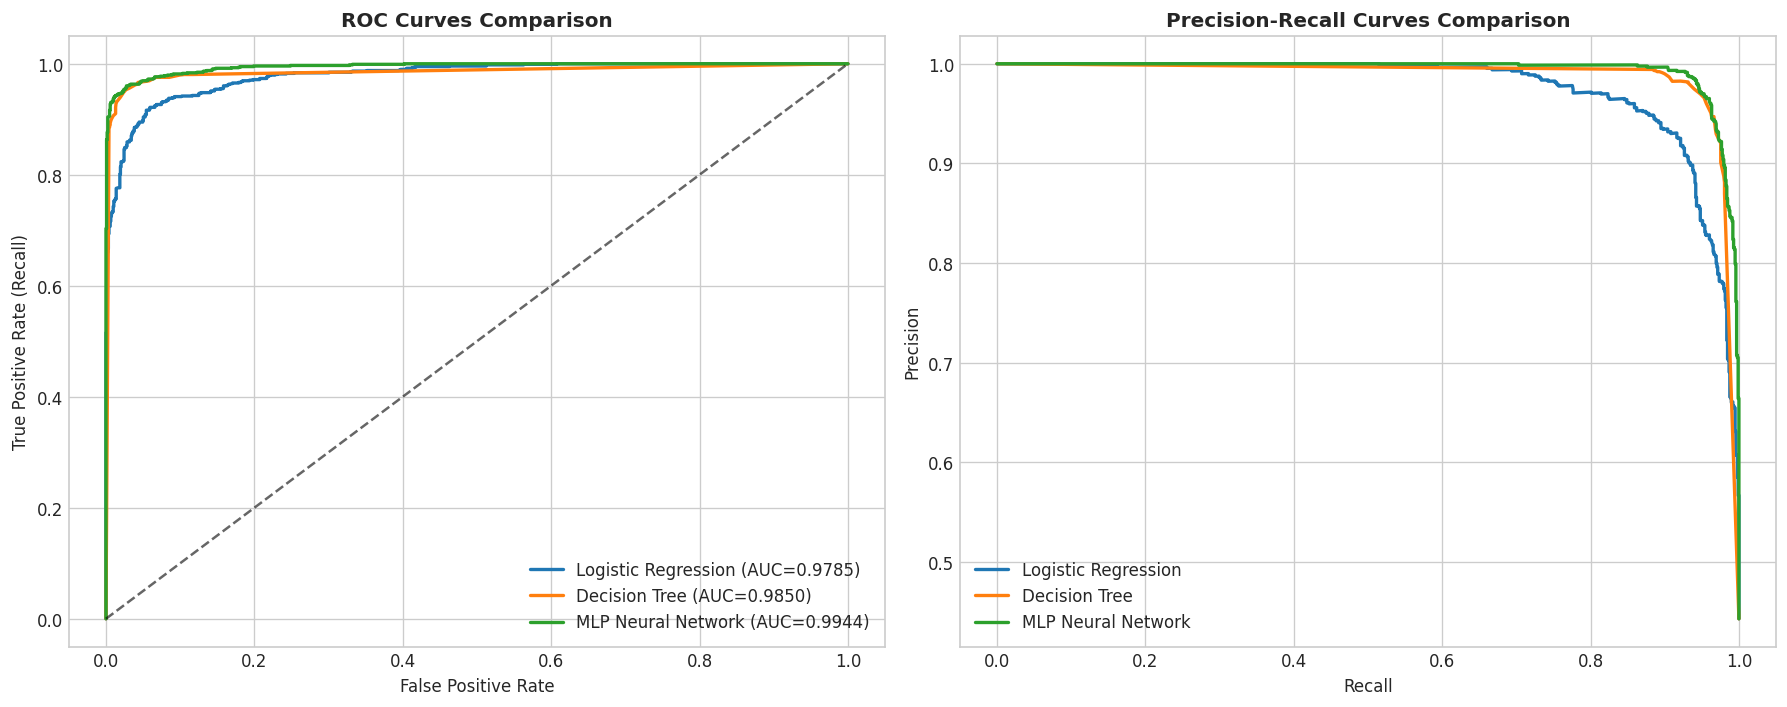

In [15]:
# ROC and PR Curves Comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=120)

for m_name, (pred, prob) in models_preds.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    prec, rec, _ = precision_recall_curve(y_test, prob)
    auc_val = roc_auc_score(y_test, prob)
    axes[0].plot(fpr, tpr, label=f'{m_name} (AUC={auc_val:.4f})', linewidth=2)
    axes[1].plot(rec, prec, label=f'{m_name}', linewidth=2)

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.6)
axes[0].set_title('ROC Curves Comparison', fontsize=12, fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend()

axes[1].set_title('Precision-Recall Curves Comparison', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend()

plt.tight_layout()
plt.show()

## 14. Feature Importance & Cyber Threat Explainability
Understanding why specific features contribute to phishing classifications across model architectures.

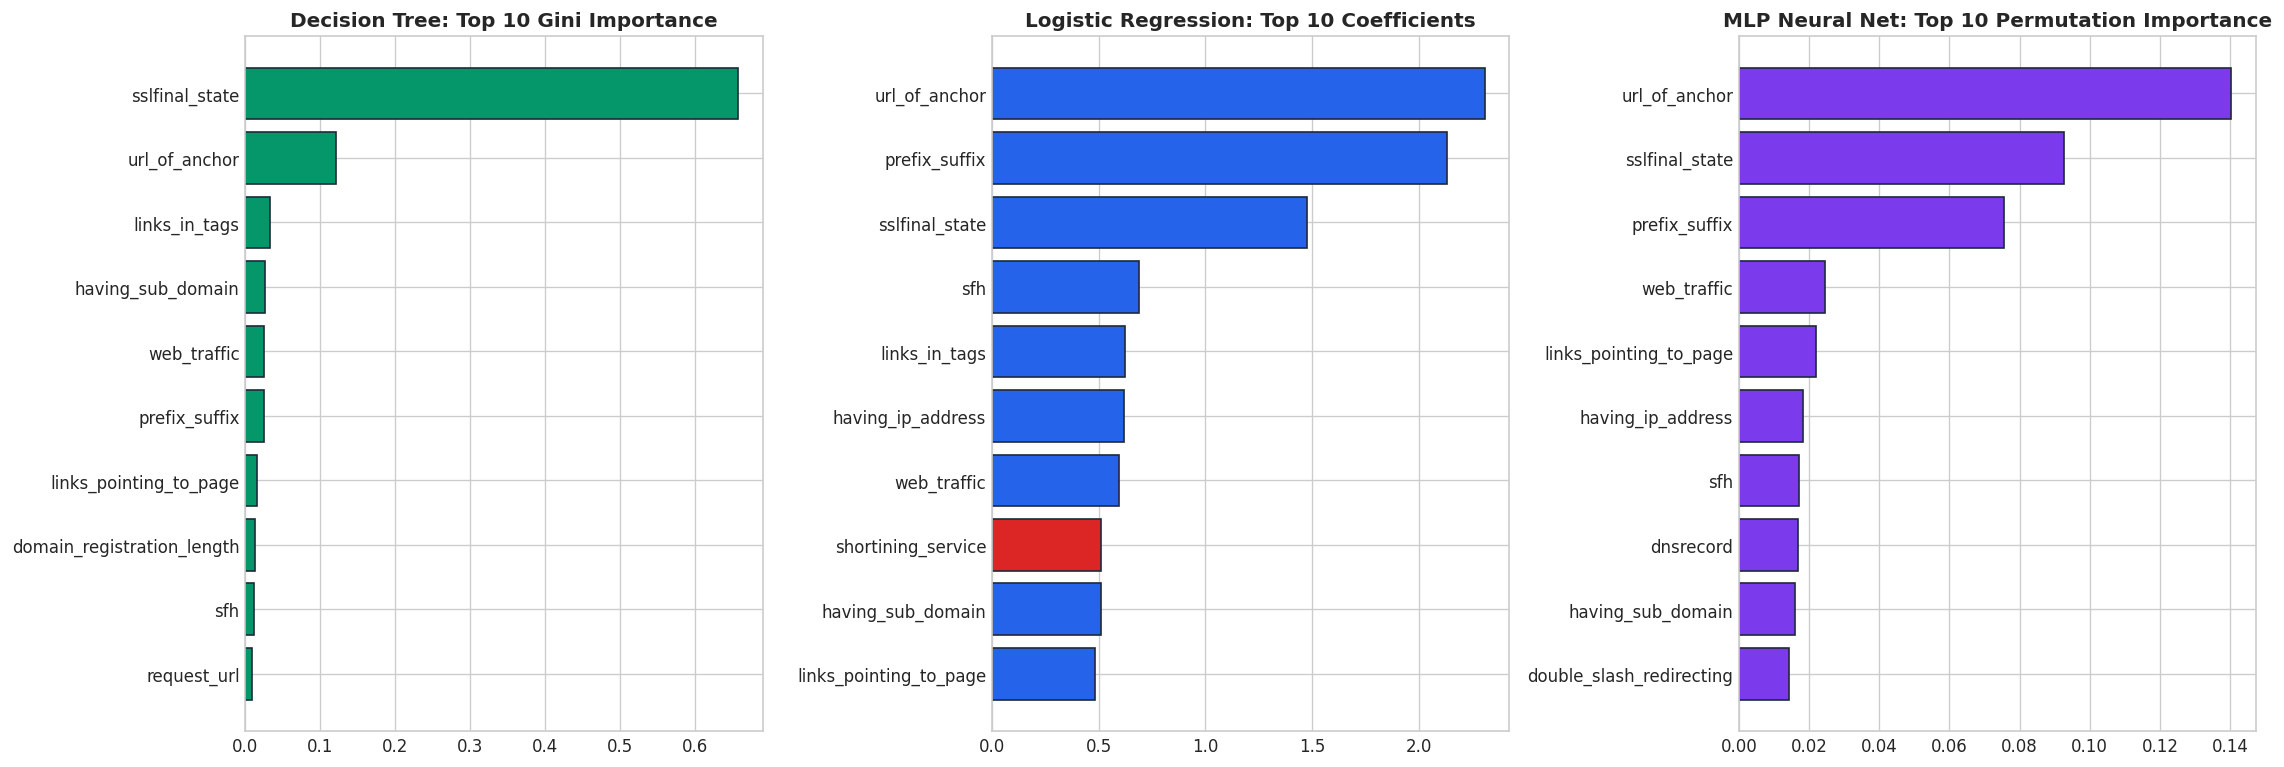

In [16]:
# 1. Decision Tree Gini Importance
dt_importance = pd.Series(dt_model.feature_importances_, index=X.columns).sort_values(ascending=False)

# 2. Logistic Regression Coefficients
lr_importance = pd.Series(lr_model.coef_[0], index=X.columns).sort_values(ascending=False)

# 3. MLP Permutation Importance on Test Set
perm_mlp = permutation_importance(mlp_model, X_test_scaled, y_test, n_repeats=5, random_state=42, scoring='f1')
mlp_importance = pd.Series(perm_mlp.importances_mean, index=X.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(19, 6.5), dpi=120)

axes[0].barh(dt_importance.head(10).index[::-1], dt_importance.head(10).values[::-1], color='#059669', edgecolor='#1e293b')
axes[0].set_title('Decision Tree: Top 10 Gini Importance', fontweight='bold')

top_lr_abs = lr_importance.abs().sort_values(ascending=False).head(10)
lr_colors = ['#dc2626' if lr_importance[f] > 0 else '#2563eb' for f in top_lr_abs.index[::-1]]
axes[1].barh(top_lr_abs.index[::-1], top_lr_abs.values[::-1], color=lr_colors, edgecolor='#1e293b')
axes[1].set_title('Logistic Regression: Top 10 Coefficients', fontweight='bold')

axes[2].barh(mlp_importance.head(10).index[::-1], mlp_importance.head(10).values[::-1], color='#7c3aed', edgecolor='#1e293b')
axes[2].set_title('MLP Neural Net: Top 10 Permutation Importance', fontweight='bold')

plt.tight_layout()
plt.show()

## 15. Ethical AI & Decision Threshold Sensitivity Simulation
In high-stakes cybersecurity applications, default classification threshold (0.50) may not align with an organization's threat posture.
- **Lower Threshold (e.g. 0.30):** High security / zero-trust. Catches virtually all phishing sites (high recall), but blocks more legitimate websites (higher false positives).
- **Higher Threshold (e.g. 0.70):** Permissive / customer-centric. Avoids blocking benign user traffic (low false positives), but permits more phishing campaigns to penetrate (high false negatives).

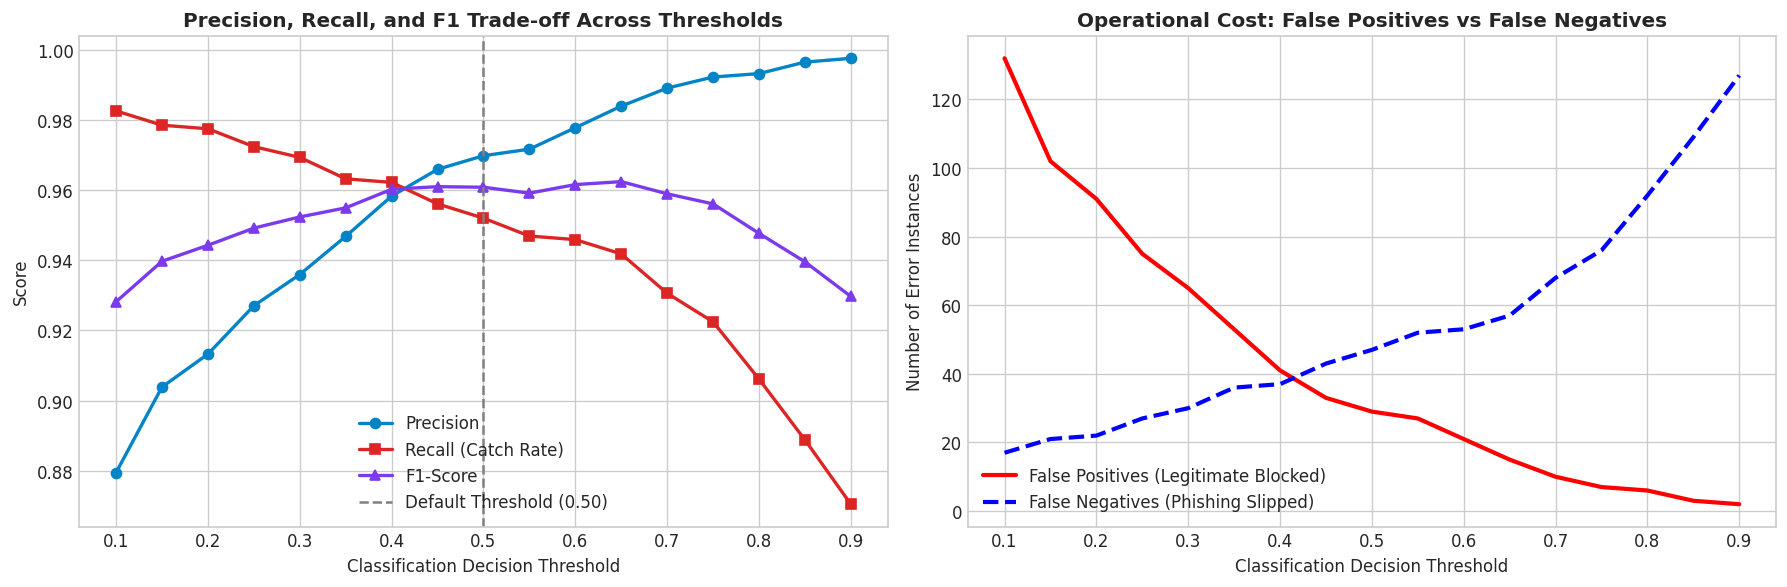

In [17]:
thresholds = np.linspace(0.1, 0.9, 17)
sim_records = []

for t in thresholds:
    t_pred = (y_prob_mlp >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, t_pred).ravel()
    sim_records.append({
        'Threshold': t,
        'Accuracy': accuracy_score(y_test, t_pred),
        'Precision': precision_score(y_test, t_pred, zero_division=0),
        'Recall': recall_score(y_test, t_pred, zero_division=0),
        'F1-Score': f1_score(y_test, t_pred, zero_division=0),
        'False Positives (Benign Blocked)': fp,
        'False Negatives (Phishing Slipped)': fn
    })

sim_df = pd.DataFrame(sim_records)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), dpi=120)

axes[0].plot(sim_df['Threshold'], sim_df['Precision'], 'o-', label='Precision', color='#0284c7', linewidth=2)
axes[0].plot(sim_df['Threshold'], sim_df['Recall'], 's-', label='Recall (Catch Rate)', color='#dc2626', linewidth=2)
axes[0].plot(sim_df['Threshold'], sim_df['F1-Score'], '^-', label='F1-Score', color='#7c3aed', linewidth=2)
axes[0].axvline(0.5, color='gray', linestyle='--', label='Default Threshold (0.50)')
axes[0].set_title('Precision, Recall, and F1 Trade-off Across Thresholds', fontweight='bold')
axes[0].set_xlabel('Classification Decision Threshold')
axes[0].set_ylabel('Score')
axes[0].legend()

axes[1].plot(sim_df['Threshold'], sim_df['False Positives (Benign Blocked)'], 'r-', label='False Positives (Legitimate Blocked)', linewidth=2.5)
axes[1].plot(sim_df['Threshold'], sim_df['False Negatives (Phishing Slipped)'], 'b--', label='False Negatives (Phishing Slipped)', linewidth=2.5)
axes[1].set_title('Operational Cost: False Positives vs False Negatives', fontweight='bold')
axes[1].set_xlabel('Classification Decision Threshold')
axes[1].set_ylabel('Number of Error Instances')
axes[1].legend()

plt.tight_layout()
plt.show()

## 16. Final Observations, Technical Synthesis & Conclusion

### Summary of Experimental Findings:
1. **Model Performance Hierarchy:**
   - **MLP Neural Network** achieved the strongest overall discrimination (Accuracy ~96.6%, Phishing Recall ~95.2%, Precision ~97.0%, ROC-AUC ~0.994), demonstrating its ability to map non-linear relationships across cybersecurity attributes.
   - **Decision Tree** delivered competitive performance (~96.3% Accuracy, ~95.1% Recall) with the lowest training latency (<0.04s) and immediate rule transparency.
   - **Logistic Regression** achieved ~92.8% Accuracy and ~90.1% Recall, serving as a reliable and lightweight baseline.

2. **Key Threat Indicators:**
   - `sslfinal_state`, `url_of_anchor`, `prefix_suffix`, and `web_traffic` emerged as the dominant indicators of phishing behavior across all models.
   - Attackers frequently compromise anchor tags and append hyphens to trusted brand names.

3. **Ethical AI & Deployment Recommendations:**
   - In financial services, critical infrastructure, and corporate gateways, adjusting the decision threshold to **0.35 - 0.40** minimizes hazardous False Negatives.
   - In open consumer browsing, calibrated thresholds around **0.50** strike an optimal balance between cybersecurity hygiene and frictionless user experience.